In [1]:
import pandas as pd

In [2]:
import pandas as pd
df=pd.read_csv("/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv")

In [3]:
df.shape

(457, 15)

In [4]:
df.describe()

,Id,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
count,4.570000e+02,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000
mean,4.628595e+09,6546.562363,4.663523,4.609847,0.179427,1.180897,0.478643,2.890197,0.001904,16.623632,13.070022,170.070022,995.282276,2189.452954
std,2.293781e+09,5398.493064,4.082072,4.068540,0.849232,2.487159,0.830995,2.237523,0.008487,28.919704,36.208635,122.205372,337.021404,815.484523
min,1.503960e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,32.000000,0.000000
25%,2.347168e+09,1988.000000,1.410000,1.280000,0.000000,0.000000,0.000000,0.870000,0.000000,0.000000,0.000000,64.000000,728.000000,1776.000000
50%,4.057193e+09,5986.000000,4.090000,4.090000,0.000000,0.000000,0.020000,2.930000,0.000000,0.000000,1.000000,181.000000,1057.000000,2062.000000
75%,6.391747e+09,10198.000000,7.160000,7.110000,0.000000,1.310000,0.670000,4.460000,0.000000,25.000000,16.000000,257.000000,1285.000000,2667.000000
max,8.877689e+09,28497.000000,27.530001,27.530001,6.727057,21.920000,6.400000,12.510000,0.100000,202.000000,660.000000,720.000000,1440.000000,4562.000000


In [5]:
df.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886


In [6]:
df[['Id', 'ActivityDate']].duplicated().sum()

np.int64(0)

In [7]:
df['SedentaryMinutes'].describe()

count     457.000000
mean      995.282276
std       337.021404
min        32.000000
25%       728.000000
50%      1057.000000
75%      1285.000000
max      1440.000000
Name: SedentaryMinutes, dtype: float64

In [8]:
df.dtypes

Id                            int64
ActivityDate                 object
TotalSteps                    int64
TotalDistance               float64
TrackerDistance             float64
LoggedActivitiesDistance    float64
VeryActiveDistance          float64
ModeratelyActiveDistance    float64
LightActiveDistance         float64
SedentaryActiveDistance     float64
VeryActiveMinutes             int64
FairlyActiveMinutes           int64
LightlyActiveMinutes          int64
SedentaryMinutes              int64
Calories                      int64
dtype: object

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        457 non-null    int64  
 1   ActivityDate              457 non-null    object 
 2   TotalSteps                457 non-null    int64  
 3   TotalDistance             457 non-null    float64
 4   TrackerDistance           457 non-null    float64
 5   LoggedActivitiesDistance  457 non-null    float64
 6   VeryActiveDistance        457 non-null    float64
 7   ModeratelyActiveDistance  457 non-null    float64
 8   LightActiveDistance       457 non-null    float64
 9   SedentaryActiveDistance   457 non-null    float64
 10  VeryActiveMinutes         457 non-null    int64  
 11  FairlyActiveMinutes       457 non-null    int64  
 12  LightlyActiveMinutes      457 non-null    int64  
 13  SedentaryMinutes          457 non-null    int64  
 14  Calories  

In [10]:
df['ActivityDate'] = pd.to_datetime(df['ActivityDate'])

In [11]:
df['TotalSteps'].describe()

count      457.000000
mean      6546.562363
std       5398.493064
min          0.000000
25%       1988.000000
50%       5986.000000
75%      10198.000000
max      28497.000000
Name: TotalSteps, dtype: float64

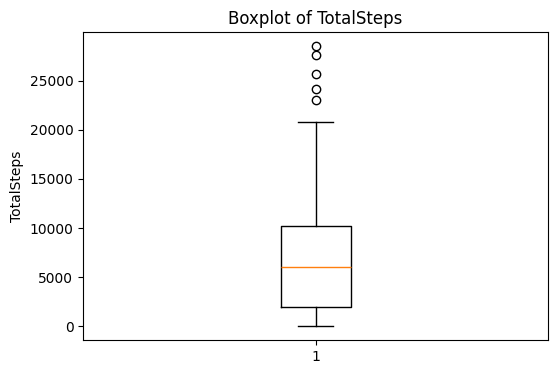

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.boxplot(df['TotalSteps'])
plt.title('Boxplot of TotalSteps')
plt.ylabel('TotalSteps')
plt.show()

In [13]:
Q1 = df['TotalSteps'].quantile(0.25)

Q3 = df['TotalSteps'].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df['TotalSteps'] >= Q1 - 1.5 * IQR) &
    (df['TotalSteps'] <= Q3 + 1.5 * IQR)
]

In [14]:
df.isnull().sum()

Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
for col in df.columns:
    unique_values = df[col].nunique()
    total_rows = len(df)

    if unique_values == total_rows:
        print(col, "→ Unique (No duplicates)")
    else:
        print(col, "→ Has duplicates")

Id → Has duplicates
ActivityDate → Has duplicates
TotalSteps → Has duplicates
TotalDistance → Has duplicates
TrackerDistance → Has duplicates
LoggedActivitiesDistance → Has duplicates
VeryActiveDistance → Has duplicates
ModeratelyActiveDistance → Has duplicates
LightActiveDistance → Has duplicates
SedentaryActiveDistance → Has duplicates
VeryActiveMinutes → Has duplicates
FairlyActiveMinutes → Has duplicates
LightlyActiveMinutes → Has duplicates
SedentaryMinutes → Has duplicates
Calories → Has duplicates


In [17]:
df[df.duplicated(keep=False)]

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories


In [18]:
df=pd.read_csv("/kaggle/input/datasets/uom190346a/sleep-health-and-lifestyle-dataset/Sleep_health_and_lifestyle_dataset.csv")

In [19]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [21]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [22]:
df.dtypes

Person ID                    int64
Gender                      object
Age                          int64
Occupation                  object
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                object
Blood Pressure              object
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder              object
dtype: object

In [23]:
df['Sleep Duration'].describe()

count    374.000000
mean       7.132086
std        0.795657
min        5.800000
25%        6.400000
50%        7.200000
75%        7.800000
max        8.500000
Name: Sleep Duration, dtype: float64

In [24]:
df['Daily Steps'].describe()

count      374.000000
mean      6816.844920
std       1617.915679
min       3000.000000
25%       5600.000000
50%       7000.000000
75%       8000.000000
max      10000.000000
Name: Daily Steps, dtype: float64

In [25]:
df['Quality of Sleep'].describe()

count    374.000000
mean       7.312834
std        1.196956
min        4.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: Quality of Sleep, dtype: float64

In [26]:
df['Stress Level'].describe()

count    374.000000
mean       5.385027
std        1.774526
min        3.000000
25%        4.000000
50%        5.000000
75%        7.000000
max        8.000000
Name: Stress Level, dtype: float64

In [27]:
df['Sleep Disorder'].value_counts(dropna=False)

Sleep Disorder
NaN            219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [28]:
df['Age'].describe()

count    374.000000
mean      42.184492
std        8.673133
min       27.000000
25%       35.250000
50%       43.000000
75%       50.000000
max       59.000000
Name: Age, dtype: float64

In [29]:
df.shape

(374, 13)

In [30]:
df['Sleep Disorder']= df['Sleep Disorder'].fillna('None')


In [31]:
df[['Systolic', 'Diastolic']] = df['Blood Pressure'].str.split('/', expand=True)

df['Systolic'] = df['Systolic'].astype(int)

df['Diastolic'] = df['Diastolic'].astype(int)

In [32]:
df.dtypes

Person ID                    int64
Gender                      object
Age                          int64
Occupation                  object
Sleep Duration             float64
Quality of Sleep             int64
Physical Activity Level      int64
Stress Level                 int64
BMI Category                object
Blood Pressure              object
Heart Rate                   int64
Daily Steps                  int64
Sleep Disorder              object
Systolic                     int64
Diastolic                    int64
dtype: object

In [33]:
df.isnull().sum()

Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
Systolic                   0
Diastolic                  0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df. duplicated().sum()

np.int64(0)

In [36]:
for col in df.columns:
    unique_values = df[col].nunique()
    total_rows = len(df)

    if unique_values == total_rows:
        print(col, "→ Unique (No duplicates)")
    else:
        print(col, "→ Has duplicates")

Person ID → Unique (No duplicates)
Gender → Has duplicates
Age → Has duplicates
Occupation → Has duplicates
Sleep Duration → Has duplicates
Quality of Sleep → Has duplicates
Physical Activity Level → Has duplicates
Stress Level → Has duplicates
BMI Category → Has duplicates
Blood Pressure → Has duplicates
Heart Rate → Has duplicates
Daily Steps → Has duplicates
Sleep Disorder → Has duplicates
Systolic → Has duplicates
Diastolic → Has duplicates


In [37]:
import pandas as pd

path = "/kaggle/input/datasets/adilshamim8/daily-food-and-nutrition-dataset/daily_food_nutrition_dataset.csv"

df = pd.read_csv(
    path,
    engine="python",      # مهم
    on_bad_lines="skip"   # يتجاوز الصفوف الخربانة
)

df.shape
df.head()

,Food_Item,Category,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Sugars (g),Sodium (mg),Cholesterol (mg),Meal_Type,Water_Intake (ml)
0,Scrambled Eggs (2 large),Protein/Dairy,180,12.0,2.0,14.0,0.0,1.0,180,370,Breakfast,250
1,Whole Wheat Toast (1 slice),Grain,80,4.0,14.0,1.0,2.0,2.0,140,0,Breakfast,0
2,Coffee (black),Beverage,5,0.3,0.0,0.1,0.0,0.0,5,0,Breakfast,0
3,Banana,Fruit,105,1.3,27.0,0.4,3.1,14.0,1,0,Breakfast,0
4,Grilled Chicken Salad,Meal/Protein,350,30.0,10.0,20.0,5.0,4.0,400,80,Lunch,500


In [38]:
df['Food_ID']=range(1,len(df)+1)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645 entries, 0 to 644
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Food_Item          645 non-null    object 
 1   Category           645 non-null    object 
 2   Calories (kcal)    645 non-null    int64  
 3   Protein (g)        645 non-null    float64
 4   Carbohydrates (g)  645 non-null    float64
 5   Fat (g)            645 non-null    float64
 6   Fiber (g)          645 non-null    float64
 7   Sugars (g)         645 non-null    float64
 8   Sodium (mg)        645 non-null    int64  
 9   Cholesterol (mg)   645 non-null    int64  
 10  Meal_Type          645 non-null    object 
 11  Water_Intake (ml)  645 non-null    int64  
 12  Food_ID            645 non-null    int64  
dtypes: float64(5), int64(5), object(3)
memory usage: 65.6+ KB


In [40]:
df.describe()

,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Sugars (g),Sodium (mg),Cholesterol (mg),Water_Intake (ml),Food_ID
count,645.000000,645.000000,645.000000,645.000000,645.000000,645.000000,645.000000,645.000000,645.000000,645.000000
mean,146.294574,6.300620,15.435194,6.469612,1.702481,5.294264,246.331783,20.482171,68.700775,323.000000
std,139.984360,8.782683,16.349230,8.142916,2.121275,8.537343,308.472431,43.560072,137.077115,186.339743
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,42.000000,0.500000,1.300000,0.200000,0.000000,0.400000,5.000000,0.000000,0.000000,162.000000
50%,105.000000,2.700000,9.200000,3.000000,1.000000,2.000000,120.000000,0.000000,0.000000,323.000000
75%,200.000000,7.000000,27.000000,10.000000,3.000000,6.000000,350.000000,25.000000,0.000000,484.000000
max,680.000000,45.000000,70.000000,40.000000,14.000000,60.000000,1580.000000,450.000000,500.000000,645.000000


In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df=df.drop_duplicates()

In [43]:
cols = ['Protein (g)', 'Fat (g)', 'Sugars (g)', 'Sodium (mg)']

invalid_rows = df[
    (df['Calories (kcal)'] == 0) &
    (df[cols] == 0).all(axis=1)
]

print(invalid_rows)

Empty DataFrame
Columns: [Food_Item, Category, Calories (kcal), Protein (g), Carbohydrates (g), Fat (g), Fiber (g), Sugars (g), Sodium (mg), Cholesterol (mg), Meal_Type, Water_Intake (ml), Food_ID]
Index: []


In [44]:
df.isnull().sum()

Food_Item            0
Category             0
Calories (kcal)      0
Protein (g)          0
Carbohydrates (g)    0
Fat (g)              0
Fiber (g)            0
Sugars (g)           0
Sodium (mg)          0
Cholesterol (mg)     0
Meal_Type            0
Water_Intake (ml)    0
Food_ID              0
dtype: int64

In [45]:
df.columns.duplicated().sum()

np.int64(0)

In [46]:
df.shape

(645, 13)

In [47]:
df.dtypes

Food_Item             object
Category              object
Calories (kcal)        int64
Protein (g)          float64
Carbohydrates (g)    float64
Fat (g)              float64
Fiber (g)            float64
Sugars (g)           float64
Sodium (mg)            int64
Cholesterol (mg)       int64
Meal_Type             object
Water_Intake (ml)      int64
Food_ID                int64
dtype: object

In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
for col in df.columns:
    unique_values = df[col].nunique()
    total_rows = len(df)

    if unique_values == total_rows:
        print(col, "→ Unique (No duplicates)")
    else:
        print(col, "→ Has duplicates")

Food_Item → Has duplicates
Category → Has duplicates
Calories (kcal) → Has duplicates
Protein (g) → Has duplicates
Carbohydrates (g) → Has duplicates
Fat (g) → Has duplicates
Fiber (g) → Has duplicates
Sugars (g) → Has duplicates
Sodium (mg) → Has duplicates
Cholesterol (mg) → Has duplicates
Meal_Type → Has duplicates
Water_Intake (ml) → Has duplicates
Food_ID → Unique (No duplicates)


In [50]:
df.columns

Index(['Food_Item', 'Category', 'Calories (kcal)', 'Protein (g)',
       'Carbohydrates (g)', 'Fat (g)', 'Fiber (g)', 'Sugars (g)',
       'Sodium (mg)', 'Cholesterol (mg)', 'Meal_Type', 'Water_Intake (ml)',
       'Food_ID'],
      dtype='object')

In [51]:
df[df.duplicated(keep=False)]

,Food_Item,Category,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Sugars (g),Sodium (mg),Cholesterol (mg),Meal_Type,Water_Intake (ml),Food_ID


In [52]:
df[df.duplicated(keep=False)].sort_values(list(df.columns))

,Food_Item,Category,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Sugars (g),Sodium (mg),Cholesterol (mg),Meal_Type,Water_Intake (ml),Food_ID


In [53]:
df=pd.read_excel("/kaggle/input/datasets/vikramamin/food-reviews-text-mining-and-sentiment-analysis/FoodReviews.xlsx")

In [54]:
df.head()

,ProductID,Helpfulness_Score,Rating,Review_Title,Text
0,CFB001E4K,1,5,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,CFB00813G,0,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,CFB000LQO,1,4,"""Delight"" says it all",This is a confection that has been around a fe...
3,CFB000UA0,3,2,Cough Medicine,If you are looking for the secret ingredient i...
4,CFB006K2Z,0,5,Great taffy,Great taffy at a great price. There was a wid...


In [55]:
import re

# Step 1: Clean_Text
df['Clean_Text'] = df['Text'].str.lower()

df['Clean_Text'] = df['Clean_Text'].str.replace(
    r'[^a-zA-Z\s]',
    '',
    regex=True
)

# Step 2: Normalized_Text
df['Normalized_Text'] = df['Clean_Text'].str.strip()

# Step 3: Refined_Text
stop_words = ['the', 'is', 'a', 'an', 'and', 'of', 'to', 'in']

df['Refined_Text'] = df['Normalized_Text'].apply(
    lambda text: ' '.join(
        word for word in text.split()
        if word not in stop_words
    )
)

# Step 4: Sentiment_Label
df['Sentiment_Label'] = df['Rating'].apply(
    lambda x: 'Positive'
    if x >= 4
    else ('Neutral' if x == 3 else 'Negative')
)

# Step 5: Sentiment_Score
df['Sentiment_Score'] = df['Sentiment_Label'].map({
    'Positive': 1,
    'Neutral': 0,
    'Negative': -1
})

# Final Structured Output
structured_reviews = df[
    [
        'ProductID',
        'Helpfulness_Score',
        'Rating',
        'Clean_Text',
        'Sentiment_Label',
        'Sentiment_Score'
    ]
]

structured_reviews.head()

,ProductID,Helpfulness_Score,Rating,Clean_Text,Sentiment_Label,Sentiment_Score
0,CFB001E4K,1,5,i have bought several of the vitality canned d...,Positive,1
1,CFB00813G,0,1,product arrived labeled as jumbo salted peanut...,Negative,-1
2,CFB000LQO,1,4,this is a confection that has been around a fe...,Positive,1
3,CFB000UA0,3,2,if you are looking for the secret ingredient i...,Negative,-1
4,CFB006K2Z,0,5,great taffy at a great price there was a wide...,Positive,1


In [56]:
df.shape

(5000, 10)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   ProductID          5000 non-null   object
 1   Helpfulness_Score  5000 non-null   int64 
 2   Rating             5000 non-null   int64 
 3   Review_Title       5000 non-null   object
 4   Text               5000 non-null   object
 5   Clean_Text         5000 non-null   object
 6   Normalized_Text    5000 non-null   object
 7   Refined_Text       5000 non-null   object
 8   Sentiment_Label    5000 non-null   object
 9   Sentiment_Score    5000 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 390.8+ KB


In [58]:
df.columns.duplicated().sum()

np.int64(0)

In [59]:
df[df.duplicated()]

,ProductID,Helpfulness_Score,Rating,Review_Title,Text,Clean_Text,Normalized_Text,Refined_Text,Sentiment_Label,Sentiment_Score
29,CFB0001PB,1,5,The Best Hot Sauce in the World,I don't know if it's the cactus or the tequila...,i dont know if its the cactus or the tequila o...,i dont know if its the cactus or the tequila o...,i dont know if its cactus or tequila or just u...,Positive,1
2309,CFB0001VW,0,2,Below standard,Too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much white pith on this orange peel making...,Negative,-1
2323,CFB0001VW,0,2,Below standard,Too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much white pith on this orange peel making...,Negative,-1
4640,CFB0002NY,0,5,LOVELY JUNIPER BERRIES,"Dried berries, still with texture and the quin...",dried berries still with texture and the quint...,dried berries still with texture and the quint...,dried berries still with texture quintessentia...,Positive,1
4641,CFB0002NY,0,5,Exaclty what i ordered,"Again, exactly what I ordered. No fuss, no mus...",again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,Positive,1
4642,CFB0002NY,0,3,get a new package,"Berries are find, but the package is bad. Unab...",berries are find but the package is bad unable...,berries are find but the package is bad unable...,berries are find but package bad unable open n...,Neutral,0


In [60]:
df[df.duplicated(keep=False)]

,ProductID,Helpfulness_Score,Rating,Review_Title,Text,Clean_Text,Normalized_Text,Refined_Text,Sentiment_Label,Sentiment_Score
10,CFB0001PB,1,5,The Best Hot Sauce in the World,I don't know if it's the cactus or the tequila...,i dont know if its the cactus or the tequila o...,i dont know if its the cactus or the tequila o...,i dont know if its cactus or tequila or just u...,Positive,1
29,CFB0001PB,1,5,The Best Hot Sauce in the World,I don't know if it's the cactus or the tequila...,i dont know if its the cactus or the tequila o...,i dont know if its the cactus or the tequila o...,i dont know if its cactus or tequila or just u...,Positive,1
2295,CFB0001VW,0,2,Below standard,Too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much white pith on this orange peel making...,Negative,-1
2309,CFB0001VW,0,2,Below standard,Too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much white pith on this orange peel making...,Negative,-1
2323,CFB0001VW,0,2,Below standard,Too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much of the white pith on this orange peel...,too much white pith on this orange peel making...,Negative,-1
4431,CFB0002NY,0,5,LOVELY JUNIPER BERRIES,"Dried berries, still with texture and the quin...",dried berries still with texture and the quint...,dried berries still with texture and the quint...,dried berries still with texture quintessentia...,Positive,1
4432,CFB0002NY,0,5,Exaclty what i ordered,"Again, exactly what I ordered. No fuss, no mus...",again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,Positive,1
4433,CFB0002NY,0,3,get a new package,"Berries are find, but the package is bad. Unab...",berries are find but the package is bad unable...,berries are find but the package is bad unable...,berries are find but package bad unable open n...,Neutral,0
4640,CFB0002NY,0,5,LOVELY JUNIPER BERRIES,"Dried berries, still with texture and the quin...",dried berries still with texture and the quint...,dried berries still with texture and the quint...,dried berries still with texture quintessentia...,Positive,1
4641,CFB0002NY,0,5,Exaclty what i ordered,"Again, exactly what I ordered. No fuss, no mus...",again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,again exactly what i ordered no fuss no muss a...,Positive,1


In [61]:
df.isnull().sum()

ProductID            0
Helpfulness_Score    0
Rating               0
Review_Title         0
Text                 0
Clean_Text           0
Normalized_Text      0
Refined_Text         0
Sentiment_Label      0
Sentiment_Score      0
dtype: int64

In [62]:
df.columns

Index(['ProductID', 'Helpfulness_Score', 'Rating', 'Review_Title', 'Text',
       'Clean_Text', 'Normalized_Text', 'Refined_Text', 'Sentiment_Label',
       'Sentiment_Score'],
      dtype='object')

In [63]:
df['Rating'].min(), df['Rating'].max()

(1, 5)

In [64]:
df['Helpfulness_Score'].min(), df['Helpfulness_Score'].max()

(0, 187)

In [65]:
df['ProductID'].duplicated().sum()

np.int64(4327)

In [66]:
df['Text'].head()

0    I have bought several of the Vitality canned d...
1    Product arrived labeled as Jumbo Salted Peanut...
2    This is a confection that has been around a fe...
3    If you are looking for the secret ingredient i...
4    Great taffy at a great price.  There was a wid...
Name: Text, dtype: object

In [67]:
df['Text'].str.len().describe()

count    5000.000000
mean      410.084200
std       408.349753
min        57.000000
25%       177.000000
50%       290.000000
75%       489.000000
max      5288.000000
Name: Text, dtype: float64

In [68]:
import pandas as pd
from difflib import SequenceMatcher

In [69]:
df=pd.read_csv("/kaggle/input/datasets/uom190346a/sleep-health-and-lifestyle-dataset/Sleep_health_and_lifestyle_dataset.csv")

In [70]:
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [71]:
import pandas as pd

df = pd.read_excel("/kaggle/input/datasets/vikramamin/food-reviews-text-mining-and-sentiment-analysis/FoodReviews.xlsx")
print(df.head())
print(df.columns)

   ProductID  Helpfulness_Score  Rating           Review_Title  \
0  CFB001E4K                  1       5  Good Quality Dog Food   
1  CFB00813G                  0       1      Not as Advertised   
2  CFB000LQO                  1       4  "Delight" says it all   
3  CFB000UA0                  3       2         Cough Medicine   
4  CFB006K2Z                  0       5            Great taffy   

                                                Text  
0  I have bought several of the Vitality canned d...  
1  Product arrived labeled as Jumbo Salted Peanut...  
2  This is a confection that has been around a fe...  
3  If you are looking for the secret ingredient i...  
4  Great taffy at a great price.  There was a wid...  
Index(['ProductID', 'Helpfulness_Score', 'Rating', 'Review_Title', 'Text'], dtype='object')


In [72]:
df=pd.read_csv("/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv")
df.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886
